<a href="https://colab.research.google.com/github/Ridhman07/IP-Lab-Assignments/blob/main/Assignment%205.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

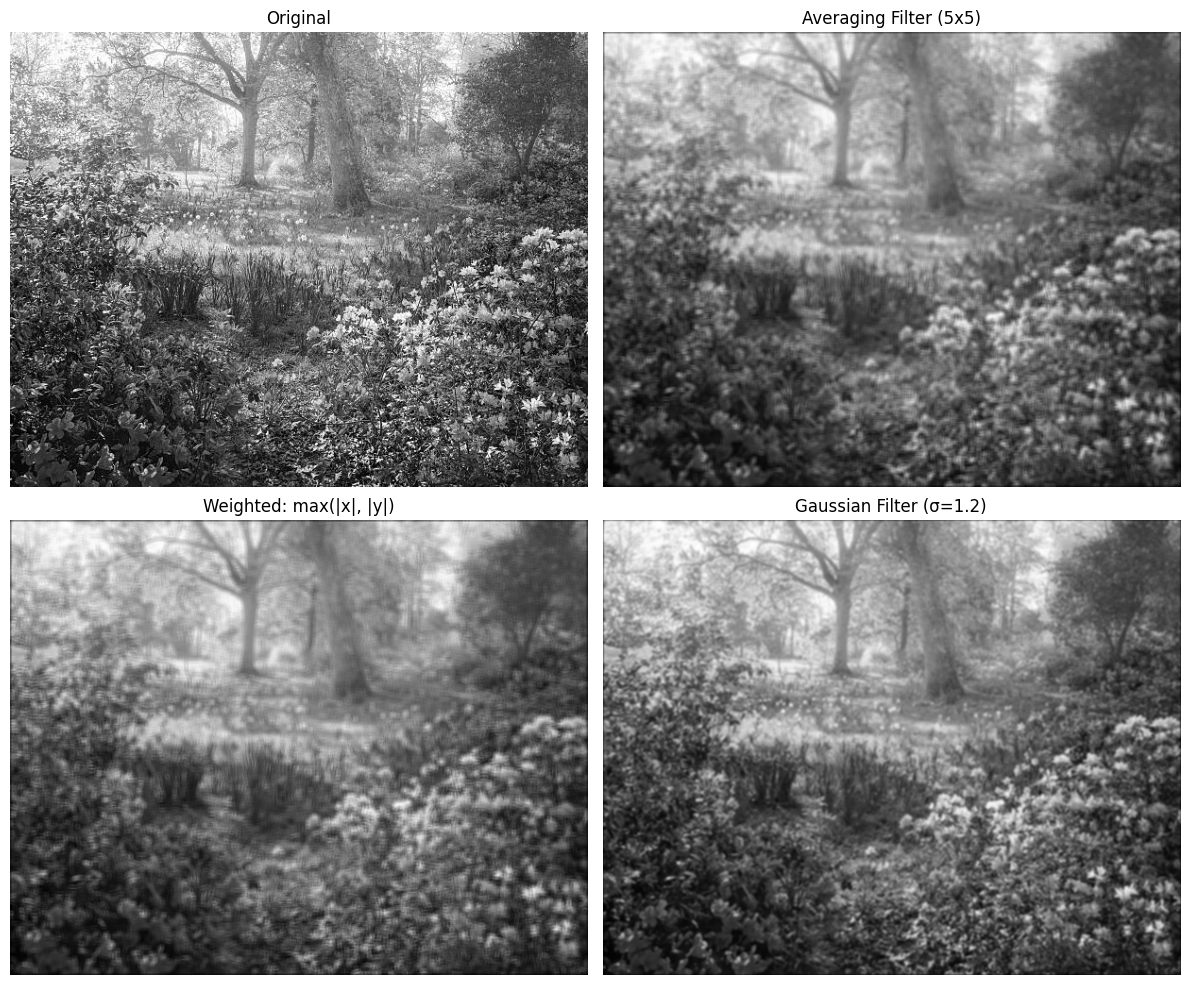

In [6]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

image_path = "/content/image.jpg"
img = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)

k_size = 5     # Filter size (must be odd)
sigma = 1.2    # Gaussian sigma
border_type = cv2.BORDER_CONSTANT  # Zero padding (or cv2.BORDER_REPLICATE)

# 1. Unweighted Averaging Filter
avg_kernel = np.ones((k_size, k_size), dtype=np.float32) / (k_size * k_size)
smooth_avg = cv2.filter2D(img, -1, avg_kernel, borderType=border_type)

# 2. Weighted Filter: h(x,y) = max(|x|, |y|)
pad = k_size // 2
custom_kernel = np.zeros((k_size, k_size), dtype=np.float32)
for i in range(k_size):
    for j in range(k_size):
        custom_kernel[i, j] = max(abs(i - pad), abs(j - pad))
custom_kernel /= np.sum(custom_kernel)
smooth_weighted = cv2.filter2D(img, -1, custom_kernel, borderType=border_type)

# 3. Gaussian Filter
smooth_gaussian = cv2.GaussianBlur(img, (k_size, k_size), sigmaX=sigma, borderType=border_type)

# Display outputs
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes[0, 0].imshow(img, cmap='gray')
axes[0, 0].set_title("Original")
axes[0, 0].axis('off')

axes[0, 1].imshow(smooth_avg, cmap='gray')
axes[0, 1].set_title(f"Averaging Filter ({k_size}x{k_size})")
axes[0, 1].axis('off')

axes[1, 0].imshow(smooth_weighted, cmap='gray')
axes[1, 0].set_title("Weighted: max(|x|, |y|)")
axes[1, 0].axis('off')

axes[1, 1].imshow(smooth_gaussian, cmap='gray')
axes[1, 1].set_title(f"Gaussian Filter (σ={sigma})")
axes[1, 1].axis('off')

plt.tight_layout()
plt.show()